In [1]:
import qgtoolbox as qg
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import xwavelet.wavelet as xwl
import xrft

from tqdm import tqdm
from matplotlib.colors import LogNorm, Normalize
from scipy.ndimage import gaussian_filter
from scipy.signal import find_peaks
from IPython.display import clear_output

dm = qg.DataManager(root_dir='..')
print(dm.root)

/home/slava/Work/climate/wavelet-jet-analysis


In [2]:
EXP = 'huge-jet-atm'
N_EPOCH = 100
METHOD = 'test'

sim_path = dm.make_dir(path=dm.raw, name=EXP)
res_path = dm.make_dir(path=dm.processed, name=EXP)
stat_path = dm.make_dir(path=res_path, name=METHOD)

cfg_path = dm.config / f"{EXP}.yaml"
ds_sim_path = sim_path / f"{EXP}.nc"
ds_stat_path = stat_path / f"{EXP}.nc"

ds_sim_path_e = qg.epoch_path(ds_sim_path, N_EPOCH)
ds_stat_path_e = qg.epoch_path(ds_stat_path, N_EPOCH)

In [3]:
def calc_spectra(ds, gamma=None, gamma_idx=None, n_scale=None, direction='x'):
    x, y = ds.x, ds.y  
    n_grid = ds.attrs['grid.n_grid']
    x0 = ds.x.values[1] - ds.x.values[0]
    if n_scale is None:
        n_scale = n_grid
    s_vals = np.geomspace(2.0, n_grid, n_scale)
    s = xr.DataArray(s_vals, dims=["s"], coords={"s": s_vals})
    Wax = xwl.cwt2(ds.ux, s, dim=['y', 'x'], x0=x0, ntheta=4, gamma=gamma, wtype='smorlet', center=False)
    Way = xwl.cwt2(ds.uy, s, dim=['y', 'x'], x0=x0, ntheta=4, gamma=gamma, wtype='smorlet', center=False)
    # Wax = xwl.cwt2_field(ds.ux, s, dim=['y', 'x'], x0=x0, ntheta=4, n_gamma=n_scale, gamma_idx=gamma_idx, wtype='smorlet', direction=direction)
    # Way = xwl.cwt2_field(ds.uy, s, dim=['y', 'x'], x0=x0, ntheta=4, n_gamma=n_scale, gamma_idx=gamma_idx, wtype='smorlet', direction=direction)
    Ea = np.abs(Wax)**2 / Wax["s"] * x0**2 + np.abs(Way)**2 / Way["s"] * x0**2
    return Ea

def plot_wspec(ds, axis, t_idx):
    k = 2 * np.pi/ds.s.values
    EEa = np.max(np.abs(ds.Eam.values))
    Eaz = ds.Eaz.isel(time=t_idx)
    Eam = ds.Eam.isel(time=t_idx)
    loglog = axis.loglog(k, Eaz/EEa, color=qg.RED, label='zonal (kx)')
    loglog = axis.loglog(k, Eam/EEa, color=qg.BLUE, label='meridional (ky)')
    axis.set_title(f'Energy Wavelet Spectrum $\\tilde E$ | $\\tilde E_0 = {EEa:.1e}$')
    axis.set_xlabel('k')
    axis.set_ylabel('E(k)')
    axis.set_ylim(1e-8, 1e1)
    axis.grid(True)
    axis.legend()
    return loglog

def plot_wspec_jet(ds, axis, t_idx):
    k = 2 * np.pi/ds.s.values
    EEa = np.max(np.abs(ds.Eam_aj.values))
    Eaz_j = ds.Eaz_j.isel(time=t_idx)
    Eam_j = ds.Eam_j.isel(time=t_idx)
    Eaz_aj = ds.Eaz_aj.isel(time=t_idx)
    Eam_aj = ds.Eam_aj.isel(time=t_idx)
    loglog = axis.loglog(k, Eam_j/EEa, color=qg.RED, label='jet (M)', linestyle='-')
    loglog = axis.loglog(k, Eaz_j/EEa, color=qg.RED, label='jet (Z)', linestyle='--')
    loglog = axis.loglog(k, Eam_aj/EEa, color=qg.BLUE, label='anti-jet (M)', linestyle='-')
    loglog = axis.loglog(k, Eaz_aj/EEa, color=qg.BLUE, label='anti-jet (Z)', linestyle='--')
    axis.set_title(f'Energy Wavelet Spectrum $\\tilde E$ | $\\tilde E_0 = {EEa:.1e}$')
    axis.set_xlabel('k')
    axis.set_ylabel('E(k)')
    axis.set_ylim(1e-8, 1e1)
    axis.grid(True)
    axis.legend()
    return loglog


In [4]:
ds = qg.load_simulation(ds_sim_path, n_epoch=10, k_epoch=91)
ds = qg.calc_statistics(ds)
ds = qg.calc_fourier(ds)
# qg.save_dataset(data=ds, path=ds_stat_path)

# ds = qg.load_dataset(ds_sim_path_e)
# ds = qg.calc_statistics(ds)
# ds = qg.calc_fourier(ds)
# qg.save_dataset(data=ds, path=ds_stat_path_e)

In [5]:
ds

<xarray.Dataset> Size: 6GB
Dimensions:  (time: 1000, y: 256, x: 256, kx: 256, ky: 256, k: 45)
Coordinates:
  * time     (time) float64 8kB 9.001e+03 9.002e+03 ... 9.999e+03 1e+04
  * y        (y) float64 2kB 0.01227 0.03682 0.06136 ... 6.222 6.246 6.271
  * x        (x) float64 2kB 0.01227 0.03682 0.06136 ... 6.222 6.246 6.271
  * kx       (kx) float64 2kB -128.0 -127.0 -126.0 -125.0 ... 125.0 126.0 127.0
  * ky       (ky) float64 2kB -128.0 -127.0 -126.0 -125.0 ... 125.0 126.0 127.0
  * k        (k) float64 360B 1.874 4.4 7.16 9.981 ... 117.4 120.2 123.0 125.9
    lev      int64 8B 1
Data variables: (12/14)
    q        (time, y, x) float64 524MB -0.2409 -0.3504 ... -0.6038 -0.5918
    ux       (time, y, x) float64 524MB 0.02535 0.02794 ... 0.0956 0.0992
    uy       (time, y, x) float64 524MB -0.01363 -0.01718 ... 0.02769 0.02382
    p        (time, y, x) float64 524MB -0.008248 -0.008622 ... -0.008434
    v        (time, y, x) float64 524MB 0.02878 0.0328 0.03846 ... 0.09953 0.102
    qp       (time, y, x) float64 524MB -0.1795 -0.289 -0.3044 ... 30.75 30.76
    ...       ...
    eh       (time, ky, kx) float64 524MB 2.603e-35 2.419e-35 ... 3.002e-35
    ehx      (time, y, kx) float64 524MB 1.118e-37 1.896e-35 ... 1.832e-35
    ehy      (time, ky, x) float64 524MB 4.312e-36 6.441e-37 ... 2.326e-37
    Ehr      (time, k) float64 360kB 1.463 4.775 0.4077 ... 8.191e-28 2.394e-32
    Ehx      (time, kx) float64 2MB 3.816e-35 7.906e-35 ... 9.384e-36 9.907e-35
    Ehy      (time, ky) float64 2MB 1.205e-35 1.648e-35 ... 3.072e-35 3.673e-35
Attributes: (12/13)
    title:                   Huge Anisotropic 2D Turbulence
    source:                  pyqg.BTModel
    architecture.n_threads:  1
    grid.n_grid:             256
    model.rek:               0.0001
    model.cnu:               0.2
    ...                      ...
    model.kf:                32.0
    model.dkf:               2.0
    model.beta:              5.0
    simulation.dt:           0.01
    simulation.t_write:      1.0
    simulation.t_epoch:      100.0

2.2 2.1475731030398975
3.2 3.399301425954581


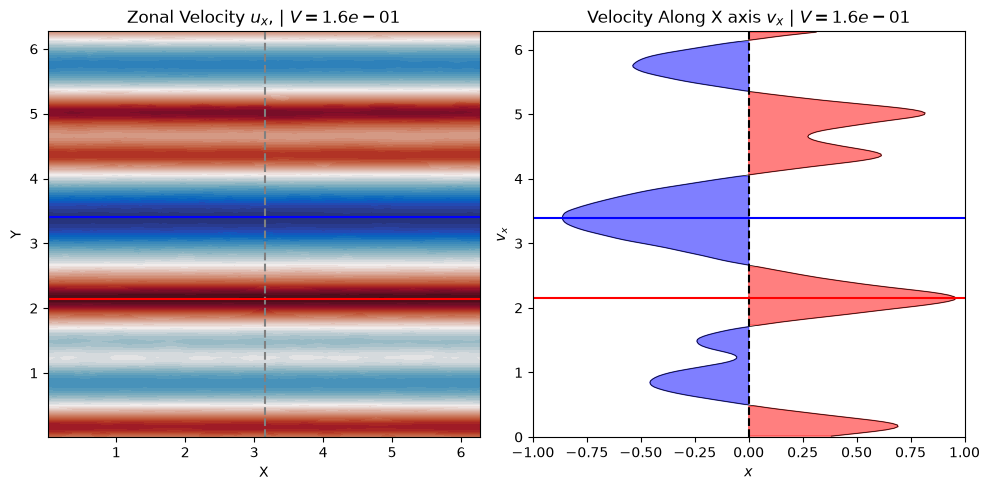

In [8]:
x0 = 128
y_j = 2.2
y_aj = 3.2
n_jets = 3
n_grid = ds.attrs['grid.n_grid']
n_times = len(ds.time)
x = ds.x.values
y = ds.y.values
V = np.abs(ds.ux).max().values

ds_m = ds.mean(dim='time').expand_dims(dim="time", axis=0)

Jet_Idx, AJet_Idx = [], []

vx = ds_m.ux.isel(time=-1, x=x0).values / V
vx_periodic = np.concatenate([vx, vx])
peaks_idx, _ = find_peaks(vx_periodic, distance=n_grid//(1.5*n_jets))
peaks_idx = peaks_idx[peaks_idx < n_grid]
top = peaks_idx[np.argsort(vx[peaks_idx])[::-1][:n_jets]]
if len(top) < n_jets:
    top = np.pad(top, (0, n_jets - len(top)), constant_values=-1)
jet_idx = np.sort(top)
j_idx = jet_idx[np.argmin(np.abs(y[jet_idx] - y_j))]

print(y_j, y[j_idx])
y_j = y[j_idx]

vx = ds_m.ux.isel(time=-1, x=x0).values / V
avx = -vx
vx_periodic = np.concatenate([avx, avx])
peaks_idx, _ = find_peaks(vx_periodic, distance=n_grid//(1.5*n_jets))
peaks_idx = peaks_idx[peaks_idx < n_grid]
top = peaks_idx[np.argsort(avx[peaks_idx])[::-1][:n_jets]]
if len(top) < n_jets:
    top = np.pad(top, (0, n_jets - len(top)), constant_values=-1)
ajet_idx = np.sort(top)
aj_idx = ajet_idx[np.argmin(np.abs(y[ajet_idx] - y_aj))]
print(y_aj, y[aj_idx])
y_aj = y[aj_idx]

for time in range(len(ds.time)):
    vx = ds.ux.isel(time=time, x=x0).values / V
    vx_periodic = np.concatenate([vx, vx])
    peaks_idx, _ = find_peaks(vx_periodic, distance=n_grid//(1.5*n_jets))
    peaks_idx = peaks_idx[peaks_idx < n_grid]
    top = peaks_idx[np.argsort(vx[peaks_idx])[::-1][:n_jets]]
    if len(top) < n_jets:
        top = np.pad(top, (0, n_jets - len(top)), constant_values=-1)
    jet_idx = np.sort(top)
    j_idx = jet_idx[np.argmin(np.abs(y[jet_idx] - y_j))]
    Jet_Idx.append(j_idx)

for time in range(len(ds.time)):
    vx = ds.ux.isel(time=time, x=x0).values / V
    avx = -vx
    vx_periodic = np.concatenate([avx, avx])
    peaks_idx, _ = find_peaks(vx_periodic, distance=n_grid//(1.5*n_jets))
    peaks_idx = peaks_idx[peaks_idx < n_grid]
    top = peaks_idx[np.argsort(avx[peaks_idx])[::-1][:n_jets]]
    if len(top) < n_jets:
        top = np.pad(top, (0, n_jets - len(top)), constant_values=-1)
    ajet_idx = np.sort(top)
    aj_idx = ajet_idx[np.argmin(np.abs(y[ajet_idx] - y_aj))]
    AJet_Idx.append(aj_idx)


fig, axis = plt.subplots(ncols=2, nrows=1, figsize=(10,5))
vel_z = qg.plot_zonal_velocity(ds_m, axis[0], t_idx=-1, x0=x0)
vel_y = qg.plot_y_velocity(ds_m, axis[1], t_idx=-1, x0=x0)
# spec = plot_wspec_jet(ds_m, axis[2], t_idx=-1)

axis[0].axhline(y_j, color='red', linestyle='-')
axis[1].axhline(y_j, color='red', linestyle='-')


axis[0].axhline(y_aj, color='blue', linestyle='-')
axis[1].axhline(y_aj, color='blue', linestyle='-')

fig.tight_layout()
# fig.savefig(stat_path / 'avg-spec.png', dpi=1000) 
plt.show()
plt.close()

In [9]:
Eaz_Jet, Eam_Jet = [], []
Eaz_AJet, Eam_AJet = [], []
n_scale = 100
for time in tqdm(range(len(ds.time))):
    jet_idx = Jet_Idx[time]
    ajet_idx = AJet_Idx[time]

    Ea_jet = calc_spectra(ds.isel(time=time), gamma=(x[x0], y_j), n_scale=n_scale)
    Eaz_jet = Ea_jet.sel(angle=0.0, method='nearest')
    Eam_jet = Ea_jet.sel(angle=np.pi/2, method='nearest')
    Eaz_Jet.append(Eaz_jet)
    Eam_Jet.append(Eam_jet)

    Ea_ajet = calc_spectra(ds.isel(time=time), gamma=(x[x0], y_aj), n_scale=n_scale)
    Eaz_ajet = Ea_ajet.sel(angle=0.0, method='nearest')
    Eam_ajet = Ea_ajet.sel(angle=np.pi/2, method='nearest')
    Eaz_AJet.append(Eaz_ajet)
    Eam_AJet.append(Eam_ajet)

Eaz_jet = xr.concat(Eaz_Jet, dim='time', data_vars='all')
Eam_jet = xr.concat(Eam_Jet, dim='time', data_vars='all')
Eaz_ajet = xr.concat(Eaz_AJet, dim='time', data_vars='all')
Eam_ajet = xr.concat(Eam_AJet, dim='time', data_vars='all')

ds['Eaz_j'] = Eaz_jet
ds['Eam_j'] = Eam_jet
ds['Eaz_aj'] = Eaz_ajet
ds['Eam_aj'] = Eam_ajet

100%|██████████| 1000/1000 [44:34<00:00,  2.67s/it]


In [10]:
ds_yjet = xr.DataArray(y_j*np.ones(len(ds.time)), dims=["time"], coords={"time":ds.time})
ds_yajet = xr.DataArray(y_aj*np.ones(len(ds.time)), dims=["time"], coords={"time":ds.time})
ds_xjet = xr.DataArray(x[x0]*np.ones(len(ds.time)), dims=["time"], coords={"time":ds.time})
ds_xajet = xr.DataArray(x[x0]*np.ones(len(ds.time)), dims=["time"], coords={"time":ds.time})
ds['x_jet'] = ds_xjet
ds['y_jet'] = ds_yjet
ds['x_ajet'] = ds_xajet
ds['y_ajet'] = ds_yajet

In [16]:
# qg.save_dataset(data=ds, path=ds_stat_path)
# ds
ds = qg.load_dataset(ds_stat_path)
ds

<xarray.Dataset> Size: 6GB
Dimensions:  (time: 1000, y: 256, x: 256, ky: 256, kx: 256, k: 45, s: 100)
Coordinates:
  * time     (time) float64 8kB 9.001e+03 9.002e+03 ... 9.999e+03 1e+04
  * y        (y) float64 2kB 0.01227 0.03682 0.06136 ... 6.222 6.246 6.271
  * x        (x) float64 2kB 0.01227 0.03682 0.06136 ... 6.222 6.246 6.271
  * ky       (ky) float64 2kB -128.0 -127.0 -126.0 -125.0 ... 125.0 126.0 127.0
  * kx       (kx) float64 2kB -128.0 -127.0 -126.0 -125.0 ... 125.0 126.0 127.0
  * k        (k) float64 360B 1.874 4.4 7.16 9.981 ... 117.4 120.2 123.0 125.9
  * s        (s) float64 800B 0.04909 0.05155 0.05414 ... 5.697 5.983 6.283
    lev      int64 8B 1
    angle    float64 8B 0.0
Data variables: (12/22)
    q        (time, y, x) float64 524MB -0.2409 -0.3504 ... -0.6038 -0.5918
    ux       (time, y, x) float64 524MB 0.02535 0.02794 ... 0.0956 0.0992
    uy       (time, y, x) float64 524MB -0.01363 -0.01718 ... 0.02769 0.02382
    p        (time, y, x) float64 524MB -0.008248 -0.008622 ... -0.008434
    v        (time, y, x) float64 524MB 0.02878 0.0328 0.03846 ... 0.09953 0.102
    qp       (time, y, x) float64 524MB -0.1795 -0.289 -0.3044 ... 30.75 30.76
    ...       ...
    Eaz_aj   (time, s) float64 800kB 5.204e-16 4.984e-16 ... 2.505e-14 3.291e-14
    Eam_aj   (time, s) float64 800kB 4.833e-16 1.467e-15 ... 1.897e-10 1.477e-10
    x_jet    (time) float64 8kB 3.154 3.154 3.154 3.154 ... 3.154 3.154 3.154
    y_jet    (time) float64 8kB 2.148 2.148 2.148 2.148 ... 2.148 2.148 2.148
    x_ajet   (time) float64 8kB 3.154 3.154 3.154 3.154 ... 3.154 3.154 3.154
    y_ajet   (time) float64 8kB 3.399 3.399 3.399 3.399 ... 3.399 3.399 3.399
Attributes: (12/13)
    title:                   Huge Anisotropic 2D Turbulence
    source:                  pyqg.BTModel
    architecture.n_threads:  1
    grid.n_grid:             256
    model.rek:               0.0001
    model.cnu:               0.2
    ...                      ...
    model.kf:                32.0
    model.dkf:               2.0
    model.beta:              5.0
    simulation.dt:           0.01
    simulation.t_write:      1.0
    simulation.t_epoch:      100.0

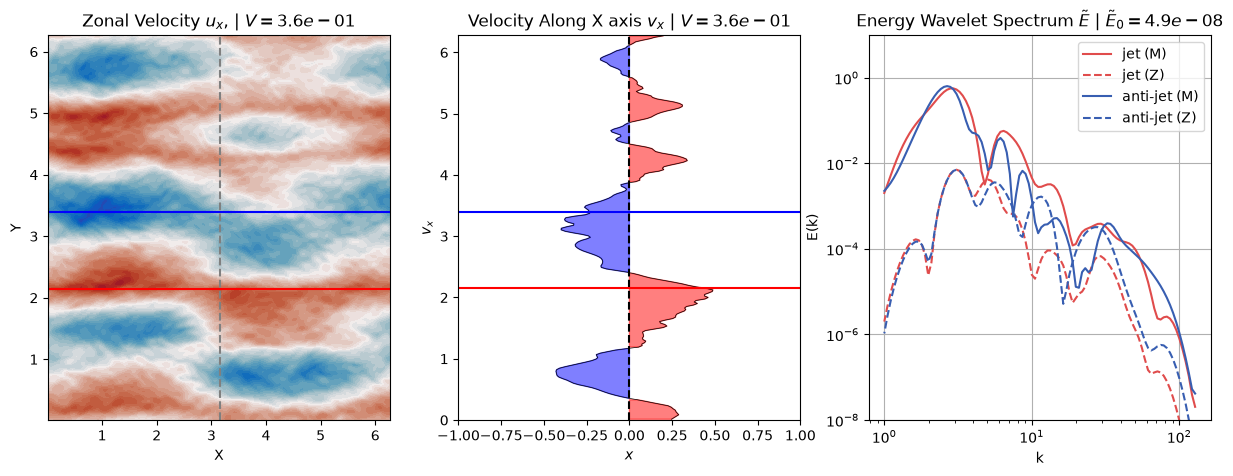

In [17]:
for time in range(100):
    clear_output(wait=True)
    fig, axis = plt.subplots(ncols=3, nrows=1, figsize=(15,5))
    vel_z = qg.plot_zonal_velocity(ds, axis[0], t_idx=time, x0=x0)
    vel_y = qg.plot_y_velocity(ds, axis[1], t_idx=time, x0=x0)
    wspec = plot_wspec_jet(ds, axis[2], t_idx=time)

    # jet_idx = Jet_Idx[time]
    axis[0].axhline(y_j, color='red', linestyle='-')
    axis[1].axhline(y_j, color='red', linestyle='-')

    # ajet_idx = AJet_Idx[time]
    axis[0].axhline(y_aj, color='blue', linestyle='-')
    axis[1].axhline(y_aj, color='blue', linestyle='-')

    plt.show()
    plt.close()

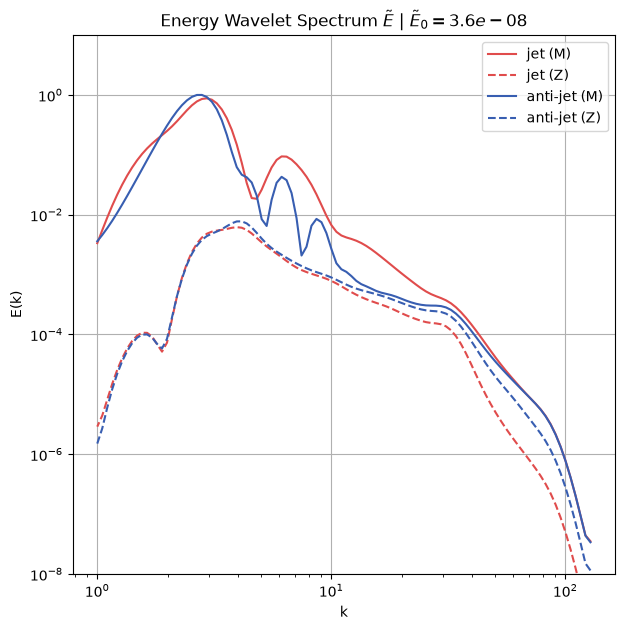

In [18]:
ds_m = ds.mean(dim='time').expand_dims(dim="time", axis=0)
fig, axis = plt.subplots(figsize=(7, 7))
plot_wspec_jet(ds_m, axis, t_idx=-1)
# fig.savefig(stat_path / 'wspec.png', dpi=1000)

In [ ]:
ds

<xarray.Dataset> Size: 577MB
Dimensions:  (time: 100, y: 256, x: 256, kx: 256, ky: 256, k: 45, s: 100)
Coordinates:
  * time     (time) float64 800B 9.901e+03 9.902e+03 ... 9.999e+03 1e+04
  * y        (y) float64 2kB 0.01227 0.03682 0.06136 ... 6.222 6.246 6.271
  * x        (x) float64 2kB 0.01227 0.03682 0.06136 ... 6.222 6.246 6.271
  * kx       (kx) float64 2kB -128.0 -127.0 -126.0 -125.0 ... 125.0 126.0 127.0
  * ky       (ky) float64 2kB -128.0 -127.0 -126.0 -125.0 ... 125.0 126.0 127.0
  * k        (k) float64 360B 1.874 4.4 7.16 9.981 ... 117.4 120.2 123.0 125.9
  * s        (s) float64 800B 0.04909 0.05155 0.05414 ... 5.697 5.983 6.283
    lev      int64 8B 1
    angle    float64 8B 0.0
Data variables: (12/22)
    q        (time, y, x) float64 52MB -0.8546 -0.6639 ... -0.6038 -0.5918
    ux       (time, y, x) float64 52MB 0.04114 0.03695 0.03512 ... 0.0956 0.0992
    uy       (time, y, x) float64 52MB -0.0589 -0.05951 ... 0.02769 0.02382
    p        (time, y, x) float64 52MB 0.02546 0.024 ... -0.009064 -0.008434
    v        (time, y, x) float64 52MB 0.07184 0.07005 0.06825 ... 0.09953 0.102
    qp       (time, y, x) float64 52MB -0.7933 -0.6026 -0.4501 ... 30.75 30.76
    ...       ...
    Eaz_aj   (time, s) float64 80kB 3.621e-17 5.33e-17 ... 2.031e-14 2.834e-14
    Eam_aj   (time, s) float64 80kB 5.501e-16 9.619e-16 ... 1.904e-10 1.475e-10
    x_jet    (time) float64 800B 3.154 3.154 3.154 3.154 ... 3.154 3.154 3.154
    y_jet    (time) float64 800B 2.172 2.172 2.172 2.172 ... 2.172 2.172 2.172
    x_ajet   (time) float64 800B 3.154 3.154 3.154 3.154 ... 3.154 3.154 3.154
    y_ajet   (time) float64 800B 3.375 3.375 3.375 3.375 ... 3.375 3.375 3.375
Attributes: (12/13)
    title:                   Huge Anisotropic 2D Turbulence
    source:                  pyqg.BTModel
    architecture.n_threads:  1
    grid.n_grid:             256
    model.rek:               0.0001
    model.cnu:               0.2
    ...                      ...
    model.kf:                32.0
    model.dkf:               2.0
    model.beta:              5.0
    simulation.dt:           0.01
    simulation.t_write:      1.0
    simulation.t_epoch:      100.0

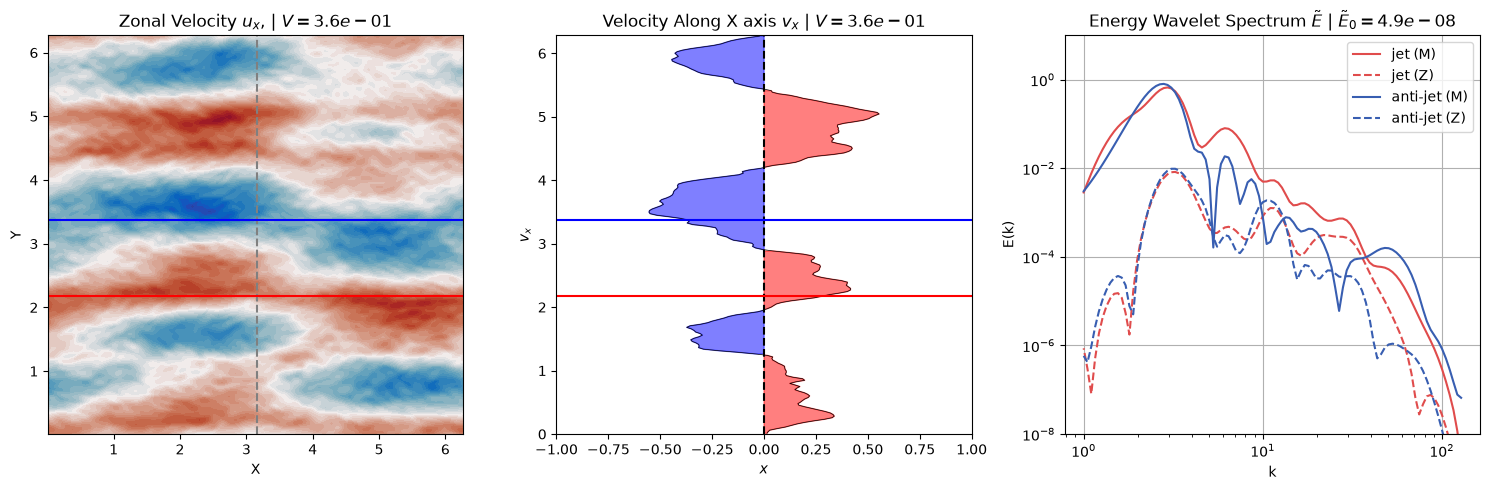

In [ ]:
for time in range(100):
    print(time)
    clear_output(wait=True)
    fig, axis = plt.subplots(ncols=3, nrows=1, figsize=(15,5))
    vel_z = qg.plot_zonal_velocity(ds, axis[0], t_idx=time, x0=x0)
    vel_y = qg.plot_y_velocity(ds, axis[1], t_idx=time, x0=x0)
    wspec = plot_wspec_jet(ds, axis[2], t_idx=time)

    # jet_idx = Jet_Idx[time]
    axis[0].axhline(y_j, color='red', linestyle='-')
    axis[1].axhline(y_j, color='red', linestyle='-')

    # ajet_idx = AJet_Idx[time]
    axis[0].axhline(y_aj, color='blue', linestyle='-')
    axis[1].axhline(y_aj, color='blue', linestyle='-')
    fig.tight_layout()
    # fig.savefig(stat_path / 'last-spec.png', dpi=1000) 
    plt.show()
    plt.close()

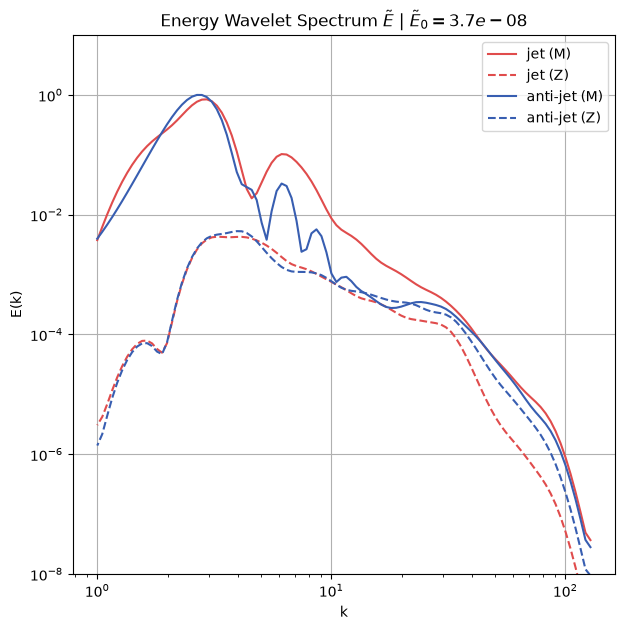

In [ ]:
ds_m = ds.mean(dim='time').expand_dims(dim="time", axis=0)
fig, axis = plt.subplots(figsize=(7, 7))
plot_wspec_jet(ds_m, axis, t_idx=-1)
# fig.savefig(stat_path / 'wspec.png', dpi=1000)